# Agro+ Brasil — Monitoramento hídrico na RMSP
## Global Solution 2026.2 · Data Science & Analytics
**Matheus Morelli Rodrigues — RM 562765** · Projeto individual · FIAP · 16/11/2026

**Notebook executado, com resultados, tabelas e gráficos incorporados.**

**Pergunta:** em que medida o histórico meteorológico de Mogi das Cruzes permite caracterizar baixa precipitação e estimar chuva semanal, como informação complementar ao monitoramento hídrico da RMSP, e quais lacunas impedem convertê-lo em alerta de escassez?

O estudo cobre aquisição, limpeza, EDA, indicadores e avaliação de Ridge e HistGradientBoosting. Os modelos foram treinados e avaliados em AGUA-03, em 06/11/2026. Esta execução **reproduz análises e confere estimativas já arquivadas**, sem novo fitting, inferência ou abertura do teste. Dados, modelos, código e métricas congelados são verificados por SHA-256.

**Conclusão de alcance:** há vantagem média retrospectiva para estimar precipitação, mas não foi validado alerta de escassez ou diagnóstico atual do abastecimento. Dados hidrológicos Sabesp foram obtidos e mantidos em quarentena, sem integração analítica.

### Como utilizar
As saídas abaixo já estão salvas: basta abrir este `.ipynb`. Para executar novamente, extraia o pacote completo, preserve a estrutura `analytics/agro-agua/`, instale `requirements-notebook.txt`, selecione esse ambiente no Jupyter/VS Code e use **Restart Kernel / Run All**. O notebook localiza o módulo automaticamente a partir de seu diretório ou da raiz do repositório. Não depende de rede nem de credenciais. Não executar os comandos históricos de treinamento.

## 1. Ambiente, rastreabilidade e proteção do experimento
O kernel confere as versões científicas originais. As guardas impedem fitting, inferência, carregamento de modelos e requisições HTTP. A comunicação local do próprio Jupyter permanece disponível.

In [1]:
from pathlib import Path
import sys, json, hashlib, inspect, platform
from importlib.metadata import version
from contextlib import ExitStack
from unittest.mock import patch
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown, Code

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((q for base in candidates for q in [base, base/'analytics/agro-agua']
             if (q/'config.json').is_file() and (q/'outputs/agua03/frozen.json').is_file()), None)
assert ROOT is not None, 'Extraia o pacote e execute a partir do módulo ou da raiz do repositório.'
sys.path.insert(0, str(ROOT))
import pipeline, eda, ml, consolidate, hydrology
import joblib, requests, urllib.request
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

def read_json(relative):
    return json.loads((ROOT/relative).read_text(encoding='utf-8'))

def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

frozen = read_json('outputs/agua03/frozen.json')
versions = pd.DataFrame([{'biblioteca': name, 'versão congelada': expected,
                         'versão atual': version(name)}
                        for name, expected in frozen['versions'].items()])
assert (versions['versão congelada'] == versions['versão atual']).all()
display(versions)
print('Python:', platform.python_version(), '| fonte: NASA POWER AG | calendário: LST')

# Guardas são reinstaladas caso a primeira célula seja executada novamente.
if '_guards' in globals():
    _guards.close()
original_train, original_evaluate = ml.train, ml.evaluate
def forbidden(*args, **kwargs):
    raise RuntimeError('Notebook congelado: treino, inferência, abertura de teste e HTTP proibidos.')
_guards = ExitStack()
for obj, method in [(Ridge,'fit'), (Ridge,'predict'), (HistGradientBoostingRegressor,'fit'),
                    (HistGradientBoostingRegressor,'predict'), (joblib,'load'),
                    (ml,'train'), (ml,'evaluate'), (ml,'predict'), (ml,'reserve_test'),
                    (requests.sessions.Session,'request'), (urllib.request,'urlopen')]:
    _guards.enter_context(patch.object(obj, method, forbidden))
pd.set_option('display.max_columns', 16)
pd.set_option('display.max_rows', 24)
pd.set_option('display.precision', 4)
print('Guardas instaladas; não há treinamento ou nova previsão nesta execução.')

,biblioteca,versão congelada,versão atual
0,scikit-learn,1.9.1,1.9.1
1,numpy,2.5.4,2.5.4
2,scipy,1.18.1,1.18.1
3,pandas,3.1.1,3.1.1
4,joblib,1.6.0,1.6.0
5,threadpoolctl,3.8.0,3.8.0


Python: 3.13.7 | fonte: NASA POWER AG | calendário: LST
Guardas instaladas; não há treinamento ou nova previsão nesta execução.


In [2]:
snapshot = read_json('outputs/entrega/preservacao-inicial.json')['files']
for relative, expected in snapshot.items():
    assert digest(ROOT/relative) == expected, relative
prior_verified = {'AGUA-01': len(read_json('data/inventory.json')),
                  'AGUA-02': ml.verify_manifest(ROOT/'outputs/agua02'),
                  'AGUA-03': ml.verify_manifest(ROOT/'outputs/agua03'),
                  'AGUA-04': consolidate.verify_inventory(ROOT/'outputs/agua04')}
ml.check_frozen(ROOT/'outputs/agua03')
print(f'{len(snapshot)} arquivos preservados byte a byte; modelos e recibos íntegros.')
display(pd.Series(prior_verified, name='arquivos no inventário').to_frame())

131 arquivos preservados byte a byte; modelos e recibos íntegros.


,arquivos no inventário
AGUA-01,78
AGUA-02,30
AGUA-03,17
AGUA-04,9


## 2. Fontes reais, território e decisão de integração

Mogi das Cruzes é o recorte municipal na RMSP. A referência NASA (-23,52°, -46,19°) é uma grade regional, não uma estação ou propriedade. O Sistema Alto Tietê foi investigado como vínculo com o abastecimento metropolitano. Disponibilidade hídrica depende de volume, vazões, retiradas, transferências e demanda: precipitação isolada não mede escassez.

| Fonte | Abrangência e variáveis | Atualização, qualidade e decisão |
|---|---|---|
| NASA POWER Daily Point, AG | 2000–2025; precipitação, Tmed/Tmax/Tmin, RH, vento, radiação | Extração 06/11/2026; LST, revisões e latência; admitida para análise retrospectiva |
| Sabesp, Alto Tietê (65), API v4 | 2025 e 01–16/11/2026; volume útil, vazão afluente/natural e chuva | Consulta 16/11/2026; `isValid=false`, semântica e janela não confirmadas; quarentena |
| SP Águas, Sala de Situação / SSD | Reservatórios e vazões | Erro TLS / HTTP 403 nos acessos registrados; sem série admitida |
| SP Águas E3-097, pluviômetro | 184/366 dias válidos em 2000; março–agosto completos | Janela de leitura desconhecida; não valida NASA por simples coincidência de data |
| INMET, catálogo | 668 estações; candidatas próximas com diferenças de relevo/ambiente | Sem série harmonizada de validação nesta investigação |

Não foram juntadas fontes com janela ou localização incompatíveis. Os exemplos de fontes do enunciado não tornam obrigatório usar todos os portais. A existência de um painel ou catálogo não comprova acesso a séries confiáveis.

In [3]:
hydro = read_json('outputs/entrega/hidrologia/quality.json')
hydro_rows = []
for item in hydro['series']:
    raw = ROOT/'outputs/entrega/hidrologia'/item['raw_file']
    assert digest(raw) == item['raw_sha256']
    payload = json.loads(raw.read_bytes())
    checked = hydrology.inspect_series(payload, item['parameter_id'], item['start'],
                                       item['end'], item['expected_days'])
    for key, value in checked.items():
        assert item[key] == value, (raw.name, key)
    hydro_rows.append({k:item[k] for k in ['system','parameter_id','unit','start','end',
                                         'records','coverage_fraction','isValid_counts',
                                         'incorporated_in_analysis']})
hydro_table = pd.DataFrame(hydro_rows)
display(hydro_table)
assert hydro_table.records.sum() == 1524
assert not hydro_table.incorporated_in_analysis.any()
print(hydro['reason'])

,system,parameter_id,unit,start,end,records,coverage_fraction,isValid_counts,incorporated_in_analysis
0,Alto Tietê,684,%,2025-01-01,2025-12-31,365,1.0,{'False': 365},False
1,Alto Tietê,691,m³/s,2025-01-01,2025-12-31,365,1.0,{'False': 365},False
2,Alto Tietê,690,m³/s,2025-01-01,2025-12-31,365,1.0,{'False': 365},False
3,Alto Tietê,1,mm,2025-01-01,2025-12-31,365,1.0,{'False': 365},False
4,Alto Tietê,684,%,2026-11-01,2026-11-16,16,1.0,{'False': 16},False
5,Alto Tietê,691,m³/s,2026-11-01,2026-11-16,16,1.0,{'False': 16},False
6,Alto Tietê,690,m³/s,2026-11-01,2026-11-16,16,1.0,{'False': 16},False
7,Alto Tietê,1,mm,2026-11-01,2026-11-16,16,1.0,{'False': 16},False


Flags isValid=false sem semântica confirmada; janela diária sem timezone. Não inferir que false comprova erro físico nem ignorar a flag.


**Interpretação:** as oito respostas têm cobertura calendárica completa nas janelas consultadas. Isso não esclarece a flag nem a janela temporal. `false` não foi tratado como prova de erro físico nem ignorado por conveniência. Nenhum valor dessa fonte participa de indicadores, EDA, treinamento ou alerta. A aquisição de 2026 não torna os indicadores NASA de 2025 atuais.

## 3. Carregamento, limpeza e integridade — AGUA-01

O código original reconstrói o calendário a partir de 26 respostas anuais, confirma configuração/proveniência, rejeita chaves/datas duplicadas e verifica `fill_value=-999`, finitude, plausibilidade e Tmin ≤ Tmed ≤ Tmax. Valores rejeitados seriam registrados antes de virar ausentes. Não se imputam zeros, não se interpolam lacunas e não se eliminam extremos silenciosamente.

`eda.audit_inputs()` executa novamente essas verificações e compara a base reconstruída aos dados processados. Os scripts originais acompanham o notebook.

In [4]:
daily, acquisition_audit = eda.audit_inputs()
assert daily.shape == (9497, 7)
quality = pd.DataFrame({'tipo':daily.dtypes.astype(str), 'válidos':daily.count(),
                        'ausentes':daily.isna().sum(), 'completude %':daily.notna().mean()*100,
                        'mínimo':daily.min(), 'máximo':daily.max(),
                        'unidade':[eda.UNITS[col] for col in daily.columns]})
display(quality)
print('Período:', daily.index.min().date(), 'a', daily.index.max().date())
print('Datas duplicadas:', daily.index.duplicated().sum(), '| valores:', daily.size)
print('Imputação: nenhuma | ocorrências:', len(acquisition_audit['quality_issues']))
display(daily.head(3))
display(daily.tail(3))

,tipo,válidos,ausentes,completude %,mínimo,máximo,unidade
PRECTOTCORR,float64,9497,0,100.0,0.00,122.29,mm/day
T2M,float64,9497,0,100.0,8.16,30.75,C
T2M_MAX,float64,9497,0,100.0,10.26,38.85,C
T2M_MIN,float64,9497,0,100.0,2.67,24.32,C
RH2M,float64,9497,0,100.0,28.58,96.57,%
WS10M,float64,9497,0,100.0,1.06,12.06,m/s
ALLSKY_SFC_SW_DWN,float64,9497,0,100.0,1.67,32.13,MJ/m^2/day


Período: 2000-01-01 a 2025-12-31
Datas duplicadas: 0 | valores: 66479
Imputação: nenhuma | ocorrências: 0


,PRECTOTCORR,T2M,T2M_MAX,T2M_MIN,RH2M,WS10M,ALLSKY_SFC_SW_DWN
date,,,,,,,
2000-01-01,36.67,21.69,23.89,20.11,92.40,3.81,10.78
2000-01-02,30.46,20.30,23.14,18.24,92.70,4.71,7.23
2000-01-03,26.12,19.18,21.63,17.78,93.66,4.20,9.73


,PRECTOTCORR,T2M,T2M_MAX,T2M_MIN,RH2M,WS10M,ALLSKY_SFC_SW_DWN
date,,,,,,,
2025-12-29,8.10,27.39,36.25,21.60,64.62,2.00,23.85
2025-12-30,3.82,27.48,34.91,22.06,67.69,1.87,25.35
2025-12-31,4.63,27.16,33.88,22.71,69.53,2.78,21.11


**Interpretação:** 9.497 dias, 66.479 valores e sete variáveis completos nesta extração. Completude e plausibilidade não demonstram exatidão local. Radiação em AG é **MJ/m²/dia**, sem conversão implícita para kWh/m²/dia; RH não é umidade do solo. A mudança solar SRB/CERES em 2001 e revisões do produto limitam hipóteses de homogeneidade.

## 4. Análise exploratória reproduzida — AGUA-02
Agregados exigem cobertura completa. Estatísticas descritivas podem usar o histórico integral; referências aplicadas a indicadores e modelos usam exclusivamente 2000–2019. Não se infere tendência ou causalidade.

In [5]:
monthly = eda.aggregate(daily, 'MS')
annual = eda.aggregate(daily, 'YS')
for computed, relative in [(monthly,'outputs/agua02/tables/monthly.csv'),
                           (annual,'outputs/agua02/tables/annual.csv')]:
    archived = pd.read_csv(ROOT/relative, index_col=0, parse_dates=[0])
    pd.testing.assert_frame_equal(computed, archived, check_freq=False,
                                  check_dtype=False, atol=1e-7, rtol=1e-10)
stats = pd.Series({'chuva média anual (mm)':annual.rain_total_mm.mean(),
                   'menor total anual (mm)':annual.rain_total_mm.min(),
                   'maior total anual (mm)':annual.rain_total_mm.max(),
                   'fração outubro-março (%)':100*daily.loc[daily.index.month.isin([10,11,12,1,2,3]),'PRECTOTCORR'].sum()/daily.PRECTOTCORR.sum(),
                   'dias P<1 mm':int(daily.PRECTOTCORR.lt(1).sum())})
display(stats.to_frame('valor'))
display(annual[['rain_total_mm','rain_max_day_mm','wet_days_ge1','max_low_run_lt1_within_period']])

,valor
chuva média anual (mm),1322.2708
menor total anual (mm),739.2800
maior total anual (mm),1908.7500
fração outubro-março (%),73.6357
dias P<1 mm,4897.0000


,rain_total_mm,rain_max_day_mm,wet_days_ge1,max_low_run_lt1_within_period
date,,,,
2000-01-01,1561.23,50.90,185,18
2001-01-01,1400.57,41.01,206,11
2002-01-01,1506.61,30.14,205,20
2003-01-01,1258.85,46.87,197,13
2004-01-01,1580.97,49.42,212,18
...,...,...,...,...
2021-01-01,931.69,23.16,154,23
2022-01-01,1224.14,42.69,192,48
2023-01-01,1231.79,37.43,176,19


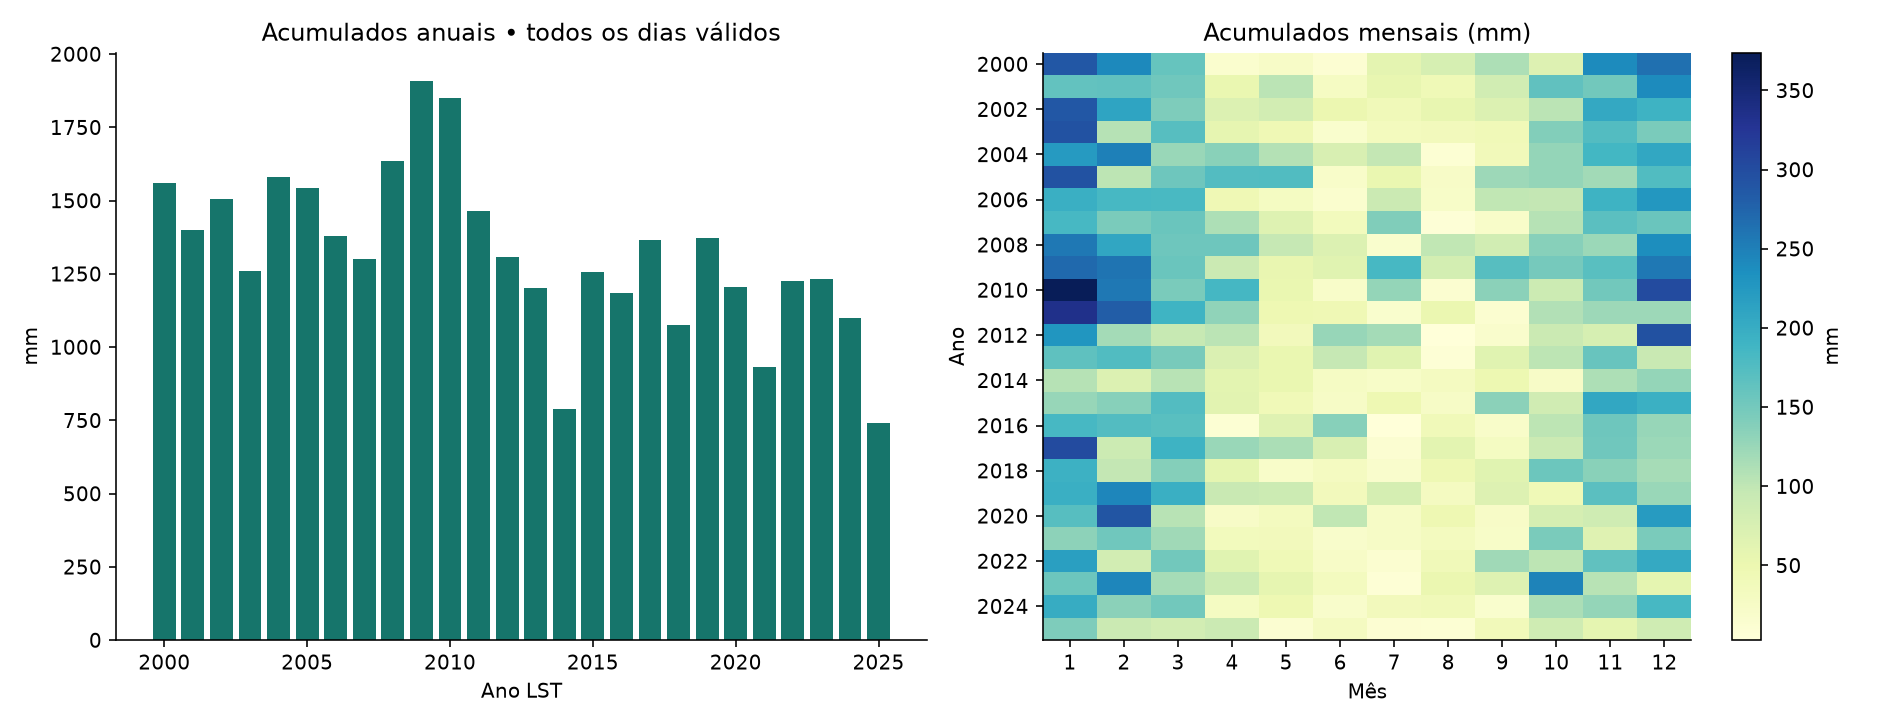

**Figura 1.** Acumulados anuais e mensais NASA; original AGUA-02, confirmado pelo inventário.

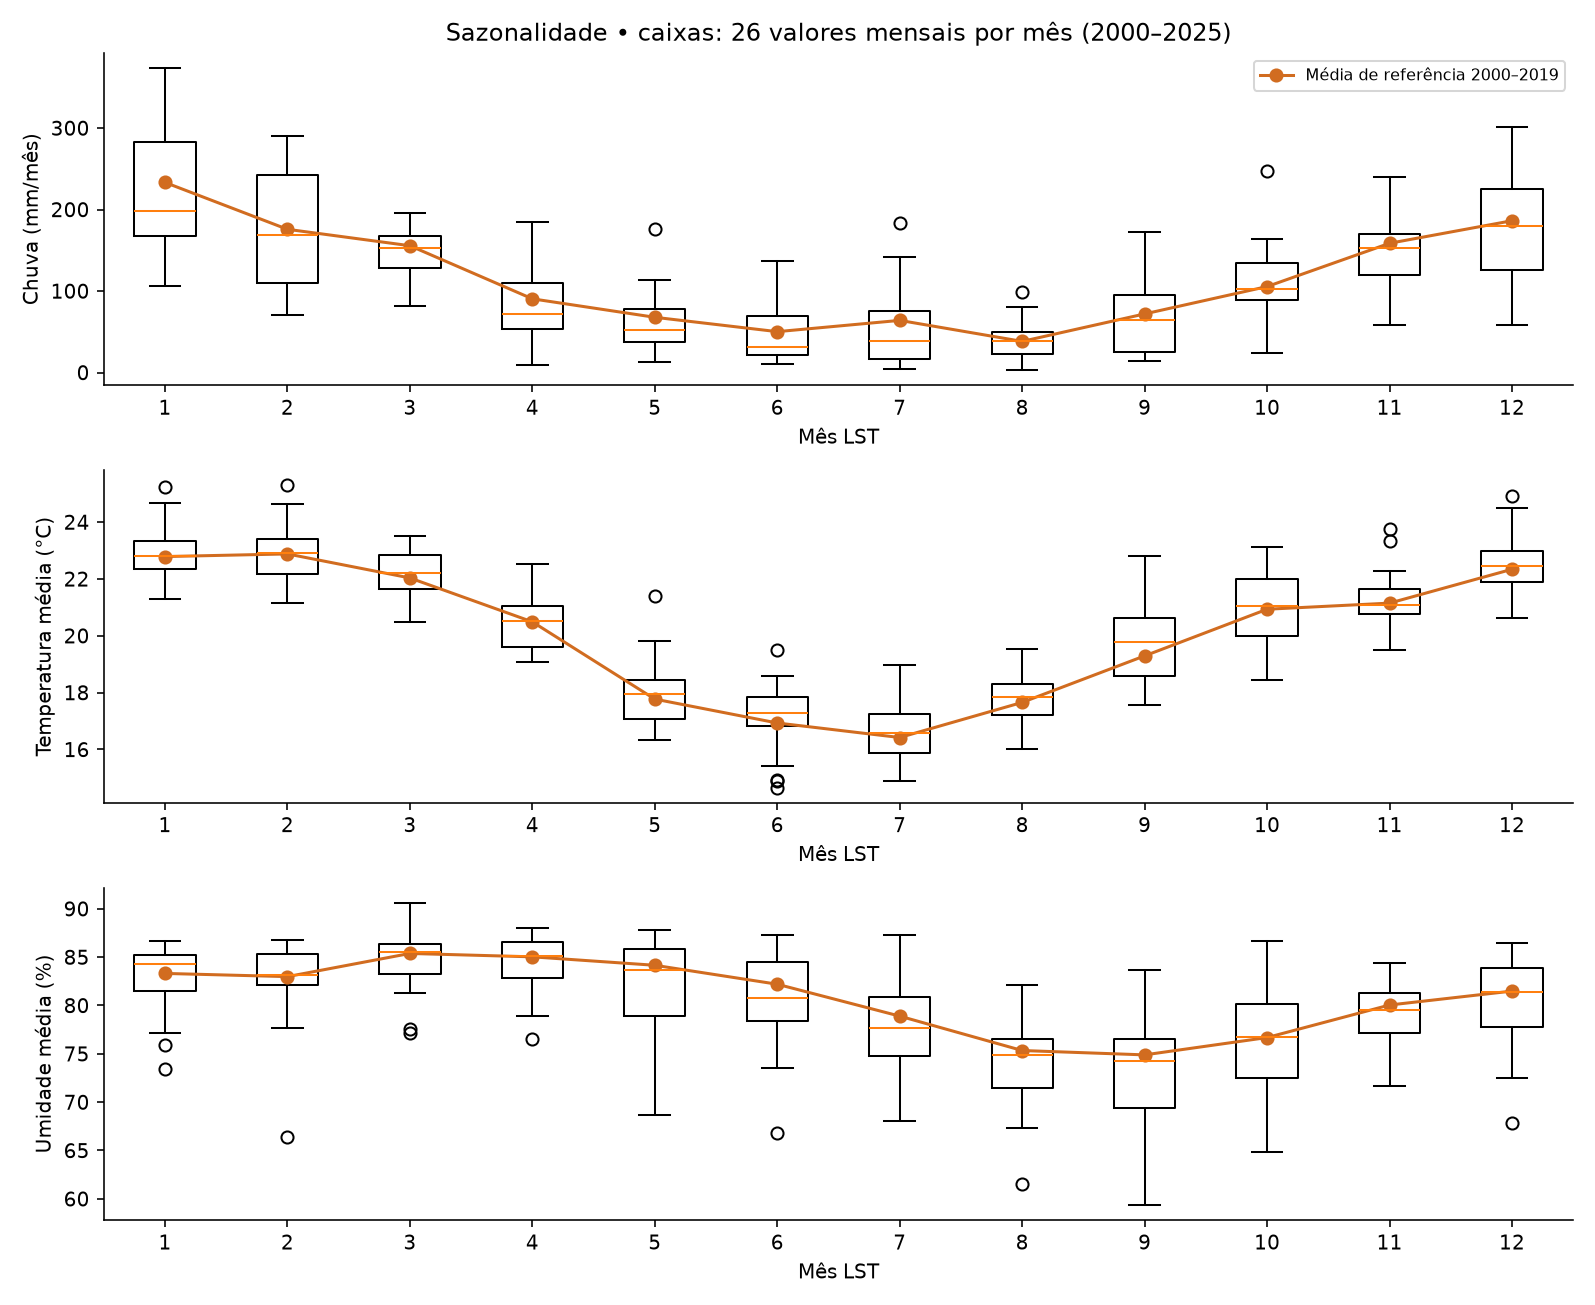

**Figura 2.** Sazonalidade de chuva, temperatura e RH; caixas com 26 valores por mês e referência 2000–2019. Extremos não foram removidos.

In [6]:
def show_figure(relative, caption):
    display(Image(filename=str(ROOT/relative), width=1000))
    display(Markdown(caption))

show_figure('outputs/agua02/figures/01_acumulados.png',
            '**Figura 1.** Acumulados anuais e mensais NASA; original AGUA-02, confirmado pelo inventário.')
show_figure('outputs/agua02/figures/02_sazonalidade.png',
            '**Figura 2.** Sazonalidade de chuva, temperatura e RH; caixas com 26 valores por mês e referência 2000–2019. Extremos não foram removidos.')

**Interpretação:** a média anual é 1.322,27 mm, com mínimo de 739,28 mm (2025) e máximo de 1.908,75 mm (2009). Outubro–março concentra 73,64% da chuva, justificando referências mensais. Esses números descrevem o produto NASA e não provam redução de reservatórios ou uma tendência climática. Os 26 anos não constituem normal oficial de 30 anos.

,start,end,days,rule,left_censored,right_censored,crosses_year
1001,2022-06-11,2022-07-28,48,P < 1 mm/day,False,False,False
578,2012-07-18,2012-08-28,42,P < 1 mm/day,False,False,False
744,2016-06-08,2016-07-15,38,P < 1 mm/day,False,False,False
745,2016-07-17,2016-08-15,30,P < 1 mm/day,False,False,False
867,2019-06-05,2019-07-03,29,P < 1 mm/day,False,False,False
713,2015-07-26,2015-08-23,29,P < 1 mm/day,False,False,False
791,2017-09-01,2017-09-28,28,P < 1 mm/day,False,False,False
920,2020-08-23,2020-09-19,28,P < 1 mm/day,False,False,False
1129,2025-06-28,2025-07-24,27,P < 1 mm/day,False,False,False
739,2016-04-02,2016-04-26,25,P < 1 mm/day,False,False,False


Maior sequência P<1: 2022-06-11 00:00:00 a 2022-07-28 00:00:00


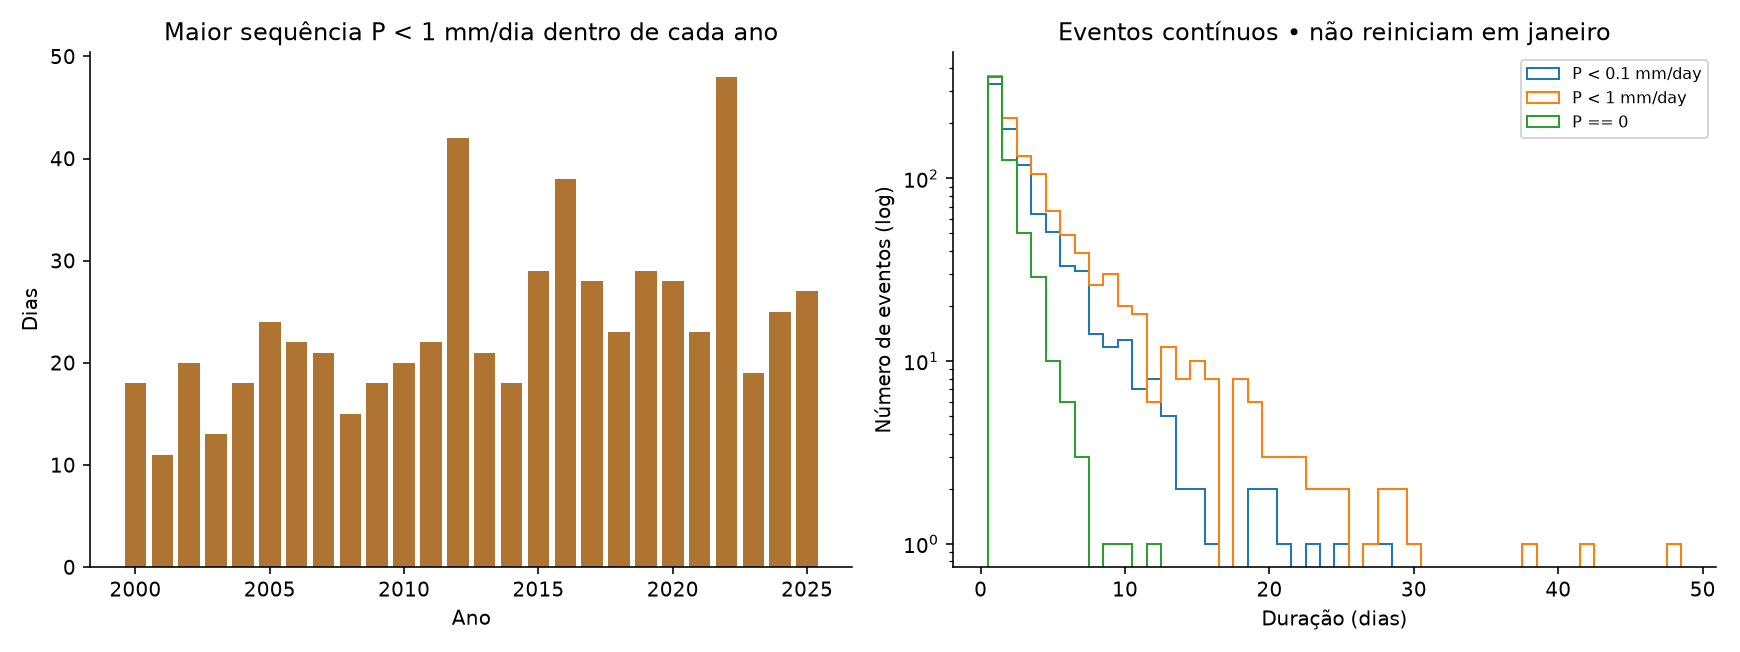

**Figura 3.** Sequências anuais e eventos contínuos; sensibilidades P<0,1 / P<1 / P=0.

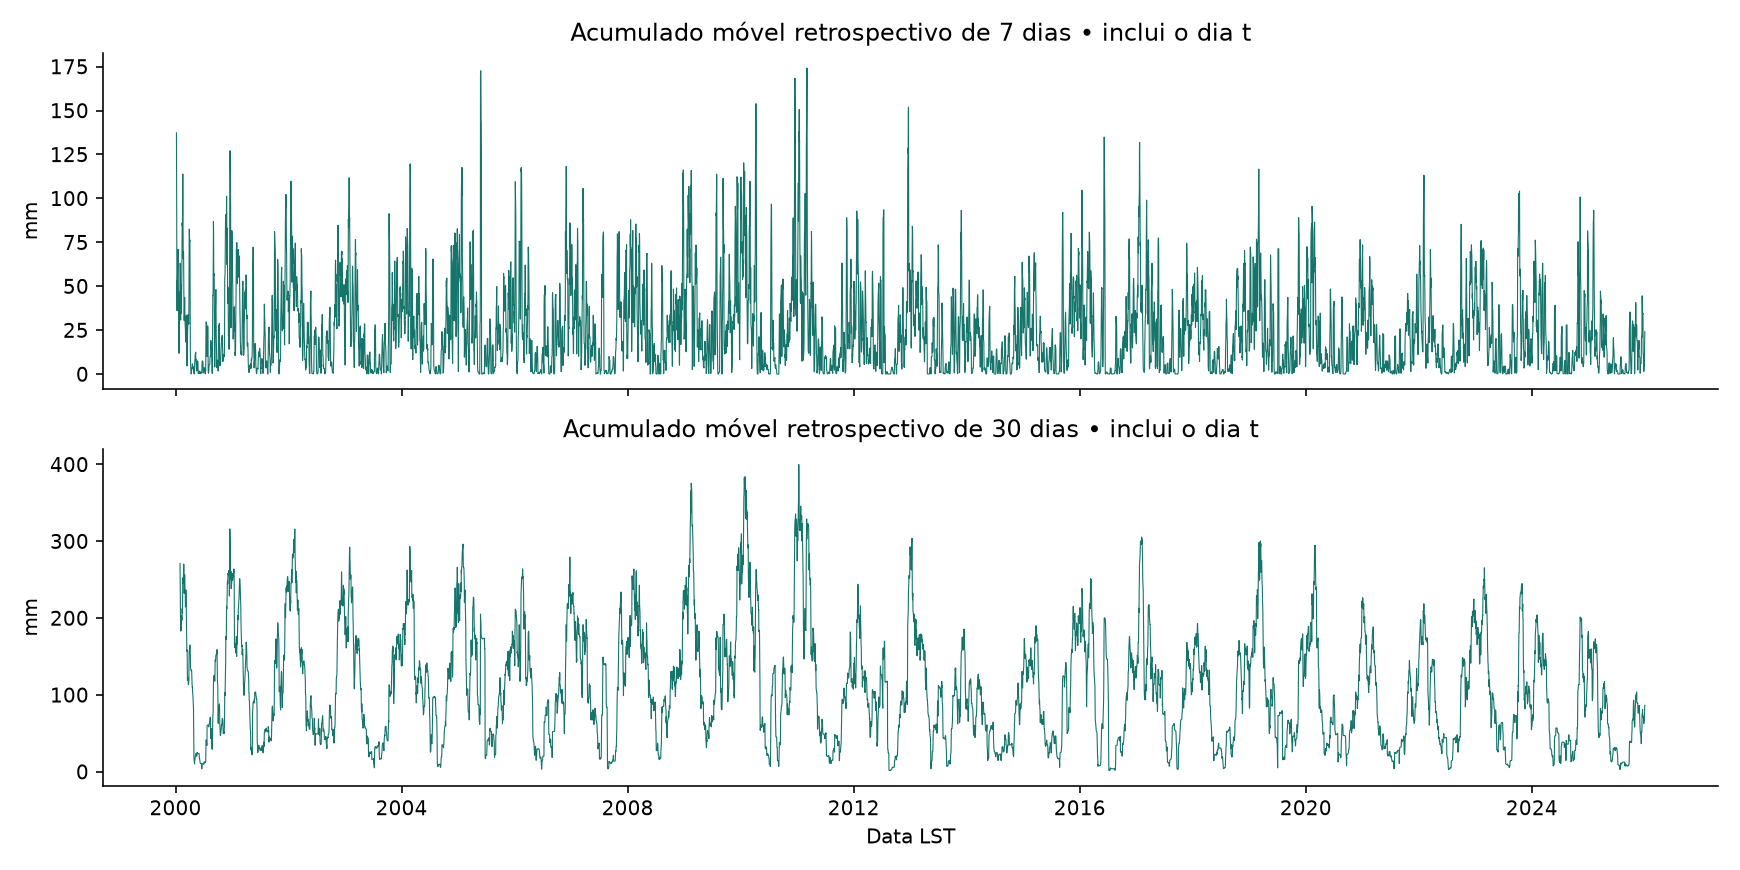

**Figura 4.** Acumulados passados de 7 e 30 dias. Janelas não são independentes.

In [7]:
events = eda.spell_events(daily.PRECTOTCORR, threshold=1.0)
events = pd.DataFrame(events).sort_values('days', ascending=False)
display(events.head(10))
longest = events.iloc[0]
assert longest['days'] == 48
print('Maior sequência P<1:', longest['start'], 'a', longest['end'])
show_figure('outputs/agua02/figures/03_sequencias_baixa_chuva.png',
            '**Figura 3.** Sequências anuais e eventos contínuos; sensibilidades P<0,1 / P<1 / P=0.')
show_figure('outputs/agua02/figures/04_acumulados_moveis.png',
            '**Figura 4.** Acumulados passados de 7 e 30 dias. Janelas não são independentes.')

**Interpretação:** a sequência máxima P<1 dura 48 dias (11/06–28/07/2022). O maior evento pode cruzar fronteiras de meses/anos; a duração máxima dentro de um ano é um indicador diferente. Eventos em bordas podem ser censurados. Pouca chuva não comprova seca no solo, dano agrícola ou falta de água; sensibilidades de limiar se sobrepõem e suas contagens não devem ser somadas.

,PRECTOTCORR,T2M,T2M_MAX,T2M_MIN,RH2M,WS10M,ALLSKY_SFC_SW_DWN
PRECTOTCORR,1.0000,0.2715,-0.0507,0.5082,0.5398,0.1482,-0.3027
T2M,0.2715,1.0000,0.8655,0.8949,-0.2313,-0.2127,0.5089
T2M_MAX,-0.0507,0.8655,1.0000,0.5913,-0.5782,-0.2575,0.6390
T2M_MIN,0.5082,0.8949,0.5913,1.0000,0.1306,-0.1107,0.2675
RH2M,0.5398,-0.2313,-0.5782,0.1306,1.0000,0.0994,-0.5291
WS10M,0.1482,-0.2127,-0.2575,-0.1107,0.0994,1.0000,-0.2140
ALLSKY_SFC_SW_DWN,-0.3027,0.5089,0.6390,0.2675,-0.5291,-0.2140,1.0000


,rain_total_mm,rain_anomaly_mm,rain_anomaly_percent,rain_anomaly_z
date,,,,
2025-01-01,142.94,-90.3110,-38.7184,-1.2736
2025-02-01,90.57,-85.1665,-48.4626,-1.2969
2025-03-01,82.00,-73.5875,-47.2965,-2.7594
2025-04-01,90.33,-0.1030,-0.1139,-0.0021
2025-05-01,12.94,-54.8320,-80.9066,-1.4488
2025-06-01,30.90,-19.2355,-38.3670,-0.5264
2025-07-01,11.20,-52.7710,-82.4921,-1.0721
2025-08-01,8.90,-29.3085,-76.7068,-1.1001
2025-09-01,38.38,-33.5335,-46.6303,-0.7405


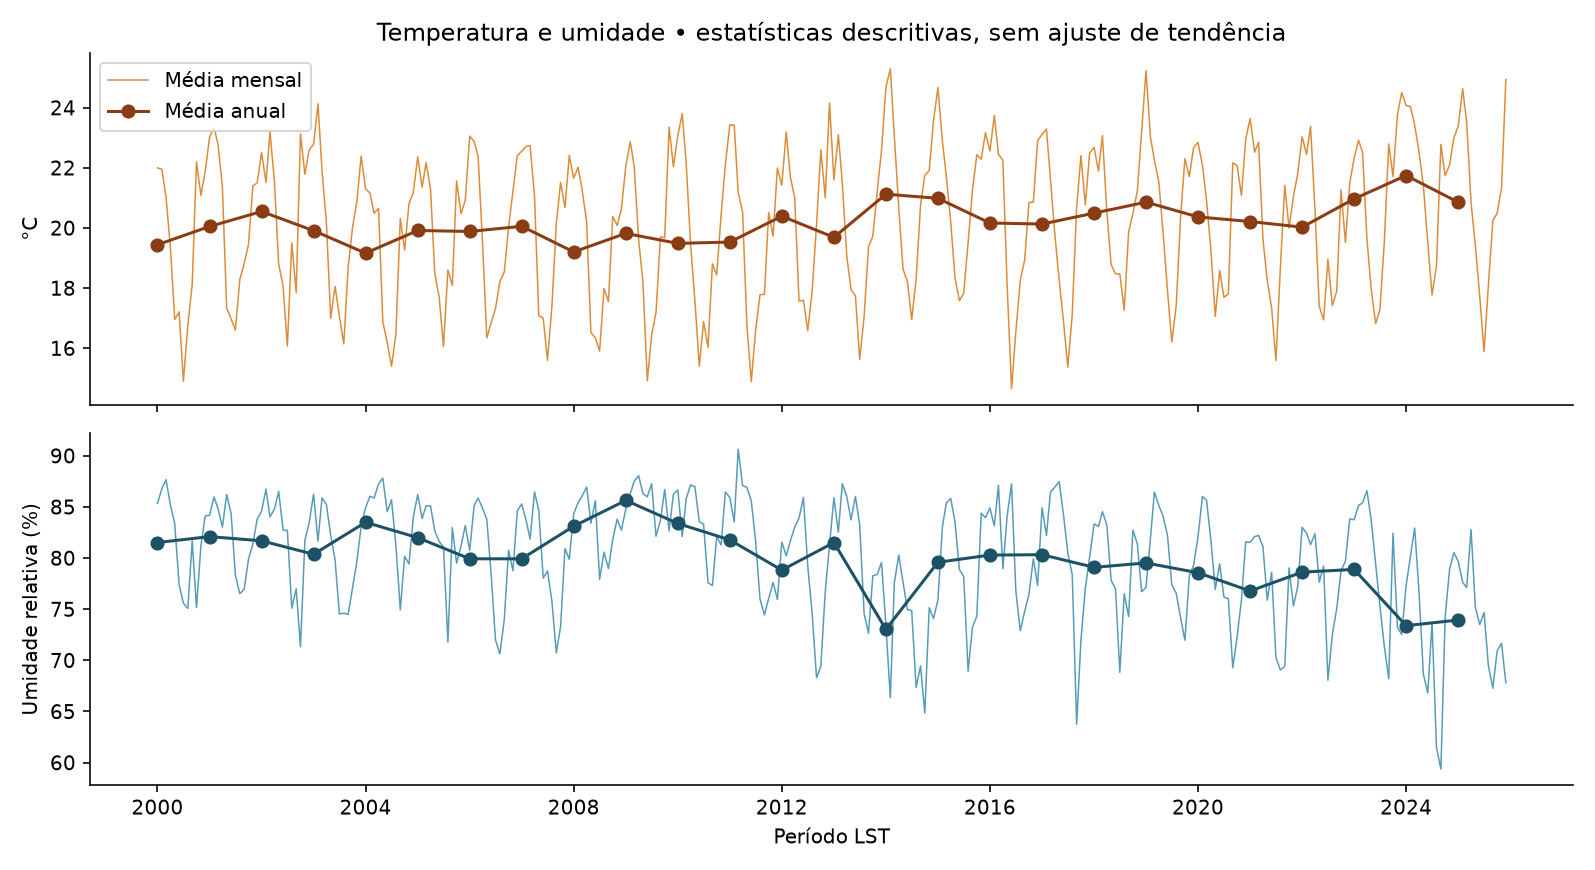

**Figura 5.** Temperatura e RH no histórico; RH é atmosférica, não umidade de solo.

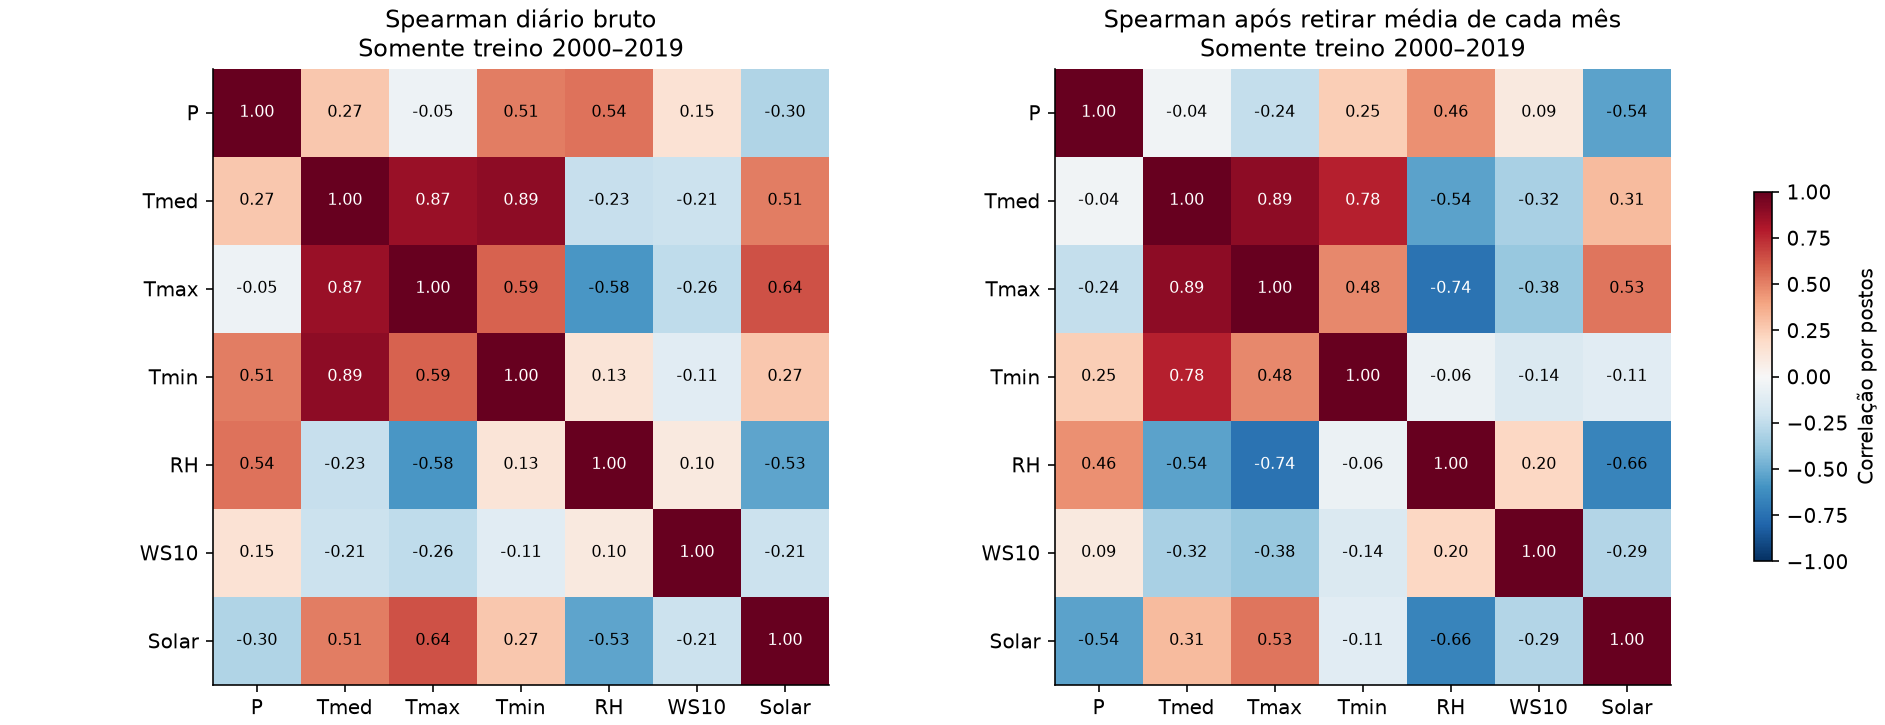

**Figura 6.** Relações apenas no treino e após remoção da média sazonal; associação não implica causalidade.

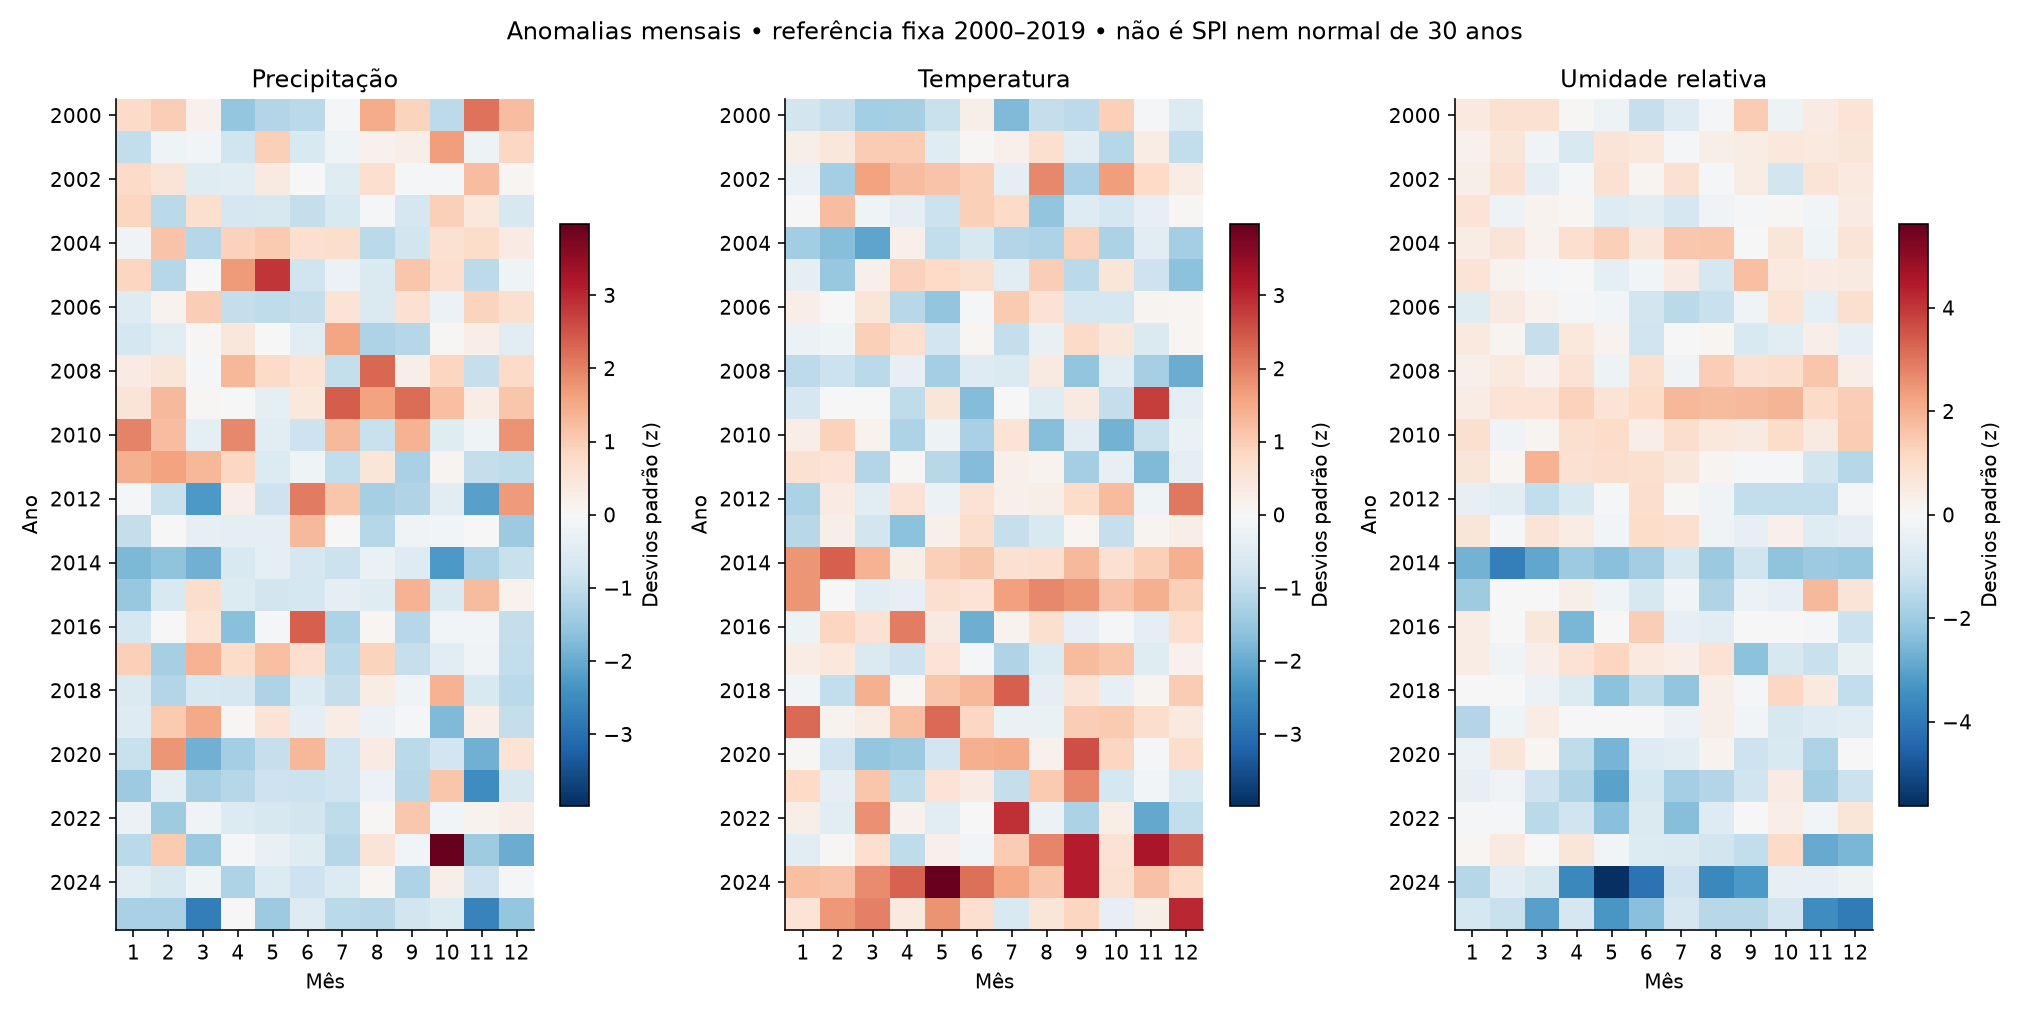

**Figura 7.** Anomalias relativas a 2000–2019. As escalas e unidades diferem por variável.

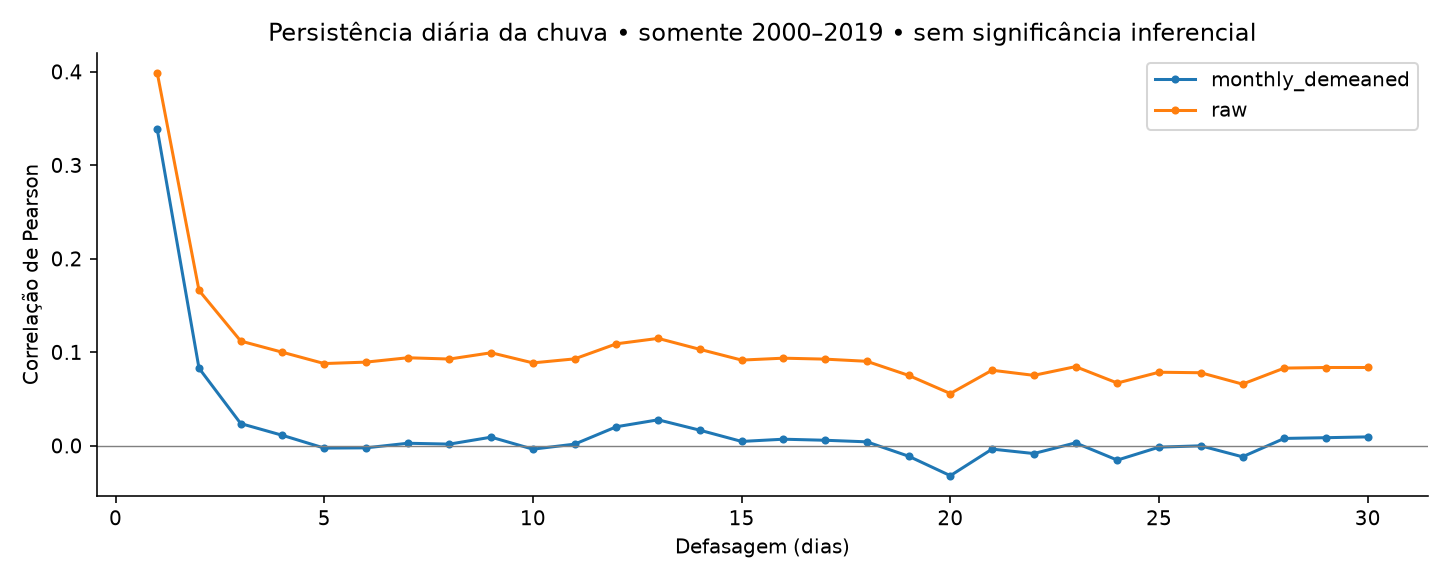

**Figura 8.** Persistência e autocorrelação no treino, com e sem média mensal.

In [8]:
train = daily.loc['2000-01-01':'2019-12-31']
monthly_reference, daily_reference, annual_reference = eda.reference_tables(
    train, eda.aggregate(train,'MS'), eda.aggregate(train,'YS'))
anomalies = eda.anomalies(monthly, monthly_reference)
spearman = train.rank().corr()
archived_corr = pd.read_csv(ROOT/'outputs/agua02/tables/spearman_train.csv', index_col=0)
pd.testing.assert_frame_equal(spearman, archived_corr, atol=1e-7, rtol=1e-10)
display(spearman)
display(anomalies[['rain_total_mm','rain_anomaly_mm','rain_anomaly_percent','rain_anomaly_z']].tail(12))
show_figure('outputs/agua02/figures/05_temperatura_umidade.png',
            '**Figura 5.** Temperatura e RH no histórico; RH é atmosférica, não umidade de solo.')
show_figure('outputs/agua02/figures/06_relacoes_treino.png',
            '**Figura 6.** Relações apenas no treino e após remoção da média sazonal; associação não implica causalidade.')
show_figure('outputs/agua02/figures/07_anomalias.png',
            '**Figura 7.** Anomalias relativas a 2000–2019. As escalas e unidades diferem por variável.')
show_figure('outputs/agua02/figures/08_persistencia_treino.png',
            '**Figura 8.** Persistência e autocorrelação no treino, com e sem média mensal.')

**Interpretação:** parte das associações brutas reflete sazonalidade compartilhada. A correlação diária lag1 da chuva cai de cerca de 0,399 para 0,338 após remover média mensal; lag7 residual é aproximadamente 0,003. Não há prova de causalidade ou previsibilidade operacional. Anomalias padronizadas não são probabilidades, SPI ou SPEI; nenhuma distribuição normal de chuva foi assumida.

## 5. Indicadores e níveis estatísticos — AGUA-04

| Indicador | Fórmula / unidade / periodicidade | Relevância e limite |
|---|---|---|
| R7/R30 | soma de P(t−j), j=0…w−1; mm; diário | Chuva recente, incluindo t; exige janela completa, sem inferir estoque de água |
| D | D(t−1)+1 quando P(t)<1; zero quando P(t)≥1; dias; diário | Duração até t, sem conhecer fim futuro; ausente interrompe sequência |
| A | soma da chuva no mês/ano encerrado; mm | Exige todos os dias; não pode ser usado como dado disponível no início do período |
| Δ, Δ%, z | A−μ; 100×(A/μ−1); (A−μ)/s | mm, %, adimensional; mensal; μ e s por mês, só 2000–2019; denominador zero implica ausente |
| Quantis | q10/q25/q75/q90 por mês final da janela | Referência empírica de treino; 20 anos por total mensal, caudas incertas |

R7/R30/A: x<q10; q10≤x<q25; q25≤x≤q75; q75<x≤q90; x>q90. Ausente/não finito recebe indisponível. Empates seguem essas desigualdades, sem forçar faixas vazias. Se q10=0, zero não fica abaixo de q10. Para D: zero, (0,q75], (q75,q90], >q90. Quantis de D incluem dias zero, não eventos independentes.

Essas faixas são **avisos estatísticos retrospectivos**, sem categorias operacionais de escassez validadas e sem limiares novos para previsões da Ridge.

In [9]:
bounds, reference = consolidate.thresholds(daily)
expected_bounds = pd.read_csv(ROOT/'outputs/agua04/thresholds.csv')
pd.testing.assert_frame_equal(bounds, expected_bounds, check_dtype=False, atol=1e-8, rtol=1e-10)
indicators = pd.DataFrame({'R7_mm':daily.PRECTOTCORR.rolling(7,min_periods=7).sum(),
                          'R30_mm':daily.PRECTOTCORR.rolling(30,min_periods=30).sum(),
                          'D_dias':eda.running_low(daily.PRECTOTCORR)})
contract = read_json('outputs/agua04/integration-example.json')
consolidate.validate_contract(contract)
assert all(not row['decision_authorized'] for row in contract['indicators'])
display(bounds.loc[bounds.calendar_month.eq(12), ['indicator','n','unit','q10','q25','q75','q90']])
display(indicators.tail(7))
display(anomalies[['rain_total_mm','rain_anomaly_mm','rain_anomaly_percent','rain_anomaly_z']].tail(1))
print('Disponibilidade do contrato:', contract['indicators'][0]['operational_availability'])

,indicator,n,unit,q10,q25,q75,q90
11,rain_7d,620,mm,15.575,25.1375,54.625,74.685
23,rain_30d,620,mm,111.420,134.8425,221.380,253.677
35,low_run,620,days,0.000,0.0000,1.000,2.000
47,monthly_rain,20,mm,121.161,126.0600,237.140,267.620


,R7_mm,R30_mm,D_dias
date,,,
2025-12-25,1.47,62.76,8.0
2025-12-26,3.94,65.78,0.0
2025-12-27,4.22,66.35,1.0
2025-12-28,7.84,70.02,0.0
2025-12-29,15.78,78.12,0.0
2025-12-30,19.59,81.94,0.0
2025-12-31,24.22,86.50,0.0


,rain_total_mm,rain_anomaly_mm,rain_anomaly_percent,rain_anomaly_z
date,,,,
2025-12-01,86.57,-99.7,-53.5245,-1.5505


Disponibilidade do contrato: retrospectivo_sem_servico


**Interpretação:** em 31/12/2025, R7=24,22 mm, R30=86,50 mm e D=0 dias. R30 fica abaixo do q10 de dezembro (111,42 mm); R7, entre q10/q25. Dezembro tem 86,57 mm, anomalia −99,70 mm (−53,52%; z≈−1,551). São sinais históricos de baixa precipitação acumulada, sem confirmação de escassez e sem representação da situação atual.

## 6. Desenho preditivo, dois modelos e protocolo congelado — AGUA-03

**Alvo:** y(t)=Σ P(t+h), h=1…7, em mm, sem incluir P(t). São 34 atributos: sete variáveis em lags 0/1/2/7, acumulados passados 7/14/30, duração baixa até t e seno/cosseno do mês. Datas-alvo, elegibilidade, baseline e bloco não são atributos.

**Ridge** é a hipótese linear regularizada, adequada a preditores correlacionados; padronização ajustada só no treino permitido, solver SVD, alpha escolhido entre 1/100. **HistGradientBoosting** testa relações não lineares e interações; sete/15 folhas foram comparadas. Early stopping aleatório foi desativado. A definição original dos algoritmos é exibida na célula abaixo.

Três folds expansivos: 2000–09→2010–12; 2000–12→2013–15; 2000–15→2016–19, com exclusão de alvos que cruzam fronteiras. Configuração por família escolhida por MAE médio nos folds; família escolhida por MAE da validação, antes da única avaliação em lote no teste. Nenhum refit com validação/teste. Previsões negativas truncadas em zero por regra prévia.

**Baselines:** climatologia de médias diárias por mês ajustadas só até 2019; persistência dos sete dias anteriores. O cenário lag0 é ideal retrospectivo, sem comprovação de que dados finais de t estavam publicados em t. Latência/vintage e sensibilidade ML lag7 permanecem não validados.

In [10]:
design, feature_columns = ml.build_design(daily)
assert len(feature_columns) == 34
counts = design.groupby('block').agg(origens=('target_next7_mm','size'),
                                   primeiro_alvo=('target_start','min'), ultimo_alvo=('target_end','max'))
assert design.block.value_counts().to_dict() == {'train':7269,'validation':1089,'test':1089}
for block, (start,end) in eda.BLOCKS.items():
    part = design.loc[design.block.eq(block)]
    assert part.target_start.min() >= pd.Timestamp(start)
    assert part.target_end.max() <= pd.Timestamp(end)
display(counts)
display(pd.DataFrame({'atributo':feature_columns}))
display(Code(inspect.getsource(ml.make_model), language='python'))
display(pd.DataFrame({name:cfg['estimator_params'] for name,cfg in frozen['configs'].items()}).fillna('—'))
print('Escolha original:', frozen['selected_model'], '| congelado em UTC:', frozen['frozen_at_utc'])

,origens,primeiro_alvo,ultimo_alvo
block,,,
test,1089,2023-01-02,2025-12-31
train,7269,2000-01-31,2019-12-31
validation,1089,2020-01-02,2022-12-31


,atributo
0,PRECTOTCORR_lag0
1,PRECTOTCORR_lag1
2,PRECTOTCORR_lag2
3,PRECTOTCORR_lag7
4,T2M_lag0
...,...
29,past_rain_30d_mm
30,low_run_so_far_lt1_days
31,calendar_sin
32,calendar_cos


def make_model(spec):
    if spec["family"] == "ridge":
        return make_pipeline(StandardScaler(), Ridge(alpha=spec["alpha"], solver="svd"))
    return HistGradientBoostingRegressor(loss="squared_error", learning_rate=.05, max_iter=150,
        max_leaf_nodes=spec["max_leaf_nodes"], min_samples_leaf=40, l2_regularization=10,
        early_stopping=False, random_state=SEED)

,ridge,hgb
scaler,StandardScaler,—
ridge_alpha,100.0,—
solver,svd,—
categorical_features,—,from_dtype
early_stopping,—,False
interaction_cst,—,—
l2_regularization,—,10
learning_rate,—,0.05
loss,—,squared_error
max_bins,—,255


Escolha original: ridge | congelado em UTC: 2026-11-06T15:02:46.571458+00:00


In [11]:
cv = pd.read_csv(ROOT/'outputs/agua03/cv_metrics.csv')
development_metrics = pd.read_csv(ROOT/'outputs/agua03/development_metrics.csv')
display(cv)
display(cv.groupby('candidate').mae_mm.mean().rename('MAE médio dos folds (mm)').to_frame())
display(development_metrics)
print('Treinamento não reexecutado; configurações e resultados de desenvolvimento são os originais.')

,candidate,fold,fit_end,evaluation_start,evaluation_end,n_fit,n,mae_mm,rmse_mm,bias_mm,r2,gain_mae_pct,gain_rmse_pct
0,ridge_1,1,2009-12-31,2010-01-01,2012-12-31,3617,1089,18.2551,26.6496,-0.5091,0.2891,0.7719,-0.1717
1,ridge_1,2,2012-12-31,2013-01-01,2015-12-31,4713,1088,15.4959,19.3169,8.1186,-0.0167,1.5768,2.5665
2,ridge_1,3,2015-12-31,2016-01-01,2019-12-31,5808,1454,14.9255,19.8002,2.9957,0.2829,6.4819,3.9746
3,ridge_100,1,2009-12-31,2010-01-01,2012-12-31,3617,1089,18.1669,26.5867,-0.5457,0.2925,1.2516,0.0645
4,ridge_100,2,2012-12-31,2013-01-01,2015-12-31,4713,1088,15.4323,19.2091,8.1500,-0.0053,1.9804,3.1103
5,ridge_100,3,2015-12-31,2016-01-01,2019-12-31,5808,1454,14.9465,19.8205,2.9816,0.2814,6.3507,3.8757
6,hgb_7,1,2009-12-31,2010-01-01,2012-12-31,3617,1089,18.1999,26.3974,-0.3693,0.3025,1.0724,0.7763
7,hgb_7,2,2012-12-31,2013-01-01,2015-12-31,4713,1088,16.3739,20.5006,9.2260,-0.1451,-4.0000,-3.4039
8,hgb_7,3,2015-12-31,2016-01-01,2019-12-31,5808,1454,15.4927,19.9850,3.6530,0.2695,2.9279,3.0782
9,hgb_15,1,2009-12-31,2010-01-01,2012-12-31,3617,1089,18.5119,26.6941,-0.3015,0.2867,-0.6237,-0.3389


,MAE médio dos folds (mm)
candidate,
hgb_15,16.8627
hgb_7,16.6888
ridge_1,16.2255
ridge_100,16.1819


,block,method,n,mae_mm,rmse_mm,bias_mm,r2,gain_mae_pct,gain_rmse_pct
0,train,climatology,7269,15.7768,21.7619,0.0371,0.2861,0.0000,0.0000
1,train,persistence,7269,20.9108,29.7983,0.0202,-0.3386,-32.5416,-36.9290
2,train,ridge,7269,15.4551,21.4572,0.0068,0.3059,2.0392,1.3998
3,train,hgb,7269,14.3048,19.7848,-0.0106,0.4099,9.3303,9.0852
4,validation,climatology,1089,13.8776,17.3790,5.4574,0.2928,0.0000,0.0000
5,validation,persistence,1089,15.4202,21.9722,-0.0388,-0.1304,-11.1159,-26.4297
6,validation,ridge,1089,12.9241,16.6623,3.4798,0.3500,6.8713,4.1239
7,validation,hgb,1089,13.7291,17.4193,5.1595,0.2895,1.0703,-0.2323


Treinamento não reexecutado; configurações e resultados de desenvolvimento são os originais.


**Justificativa da seleção:** Ridge alpha=100 foi escolhida na validação antes de abrir o teste. O HGB escolhido usa sete folhas, 150 iterações, taxa 0,05, mínimo 40 amostras/folha, L2=10 e seed=562765. O teste não foi usado para escolher novamente o vencedor. As métricas de treino são aparentes/in-sample, não backtest.

## 7. Reprodução das métricas e avaliação crítica

As estimativas são lidas dos CSVs cujos hashes já foram conferidos. MAE é a métrica primária em mm; RMSE pesa mais erros grandes; viés = estimado−real; R² mede ajuste relativo à variação do alvo. Ganho MAE=100×(1−MAE_modelo/MAE_climatologia). Não se usa MAPE com chuva zero. A célula recalcula todos os recortes originais, sem nova inferência.

In [12]:
development_predictions = pd.read_csv(ROOT/'outputs/agua03/development_predictions.csv',parse_dates=['date'])
test_predictions = pd.read_csv(ROOT/'outputs/agua03/test_predictions.csv',parse_dates=['date'])
all_predictions = pd.concat([development_predictions,test_predictions],ignore_index=True)
metrics = ml.detailed_metrics(all_predictions, frozen['q90_high_rain_train_mm'])
archived_metrics = pd.read_csv(ROOT/'outputs/agua03/metrics.csv')
pd.testing.assert_frame_equal(metrics,archived_metrics,check_dtype=False,atol=1e-10,rtol=1e-10)
test_all = metrics.loc[metrics.block.eq('test') & metrics.group.eq('all')]
display(test_all[['method','n','mae_mm','rmse_mm','bias_mm','r2','gain_mae_pct']])
display(metrics.loc[metrics.group.eq('all'),['block','method','n','mae_mm','gain_mae_pct']])
display(Code(inspect.getsource(ml.scores), language='python'))
print('Todas as métricas e recortes coincidem com os registros congelados.')

,method,n,mae_mm,rmse_mm,bias_mm,r2,gain_mae_pct
0,climatology,1089,15.8069,19.5278,7.1682,0.0964,0.0000
1,persistence,1089,15.9605,22.4004,0.2812,-0.1890,-0.9712
2,ridge,1089,14.2446,18.0685,5.6503,0.2264,9.8836
3,hgb,1089,15.0954,19.0388,6.9201,0.1411,4.5013


,block,method,n,mae_mm,gain_mae_pct
0,test,climatology,1089,15.8069,0.0000
1,test,persistence,1089,15.9605,-0.9712
2,test,ridge,1089,14.2446,9.8836
3,test,hgb,1089,15.0954,4.5013
56,train,climatology,7269,15.7768,0.0000
57,train,persistence,7269,20.9108,-32.5416
58,train,ridge,7269,15.4551,2.0392
59,train,hgb,7269,14.3048,9.3303
180,validation,climatology,1089,13.8776,0.0000
181,validation,persistence,1089,15.4202,-11.1159


def scores(y, prediction, climate):
    y, prediction, climate = map(lambda x: np.asarray(x, dtype=float), (y, prediction, climate))
    if len(y) == 0 or not np.isfinite(np.concatenate([y, prediction, climate])).all():
        raise ValueError("Métricas exigem pares finitos e não vazios")
    errors = prediction-y
    mae, rmse = np.mean(abs(errors)), np.sqrt(np.mean(errors**2))
    base_mae, base_rmse = np.mean(abs(climate-y)), np.sqrt(np.mean((climate-y)**2))
    denominator = np.sum((y-y.mean())**2)
    return {"n": len(y), "mae_mm": float(mae), "rmse_mm": float(rmse), "bias_mm": float(errors.mean()),
        "r2": float(1-np.sum(errors**2)/denominator) if denominator > 0 else None,
        "gain_mae_pct": float(100*(1-mae/base_mae)) if base_mae > 0 else None,
        "gain_rmse_pct": float(100*(1-rmse/base_rmse)) if base_rmse > 0 else None}

Todas as métricas e recortes coincidem com os registros congelados.


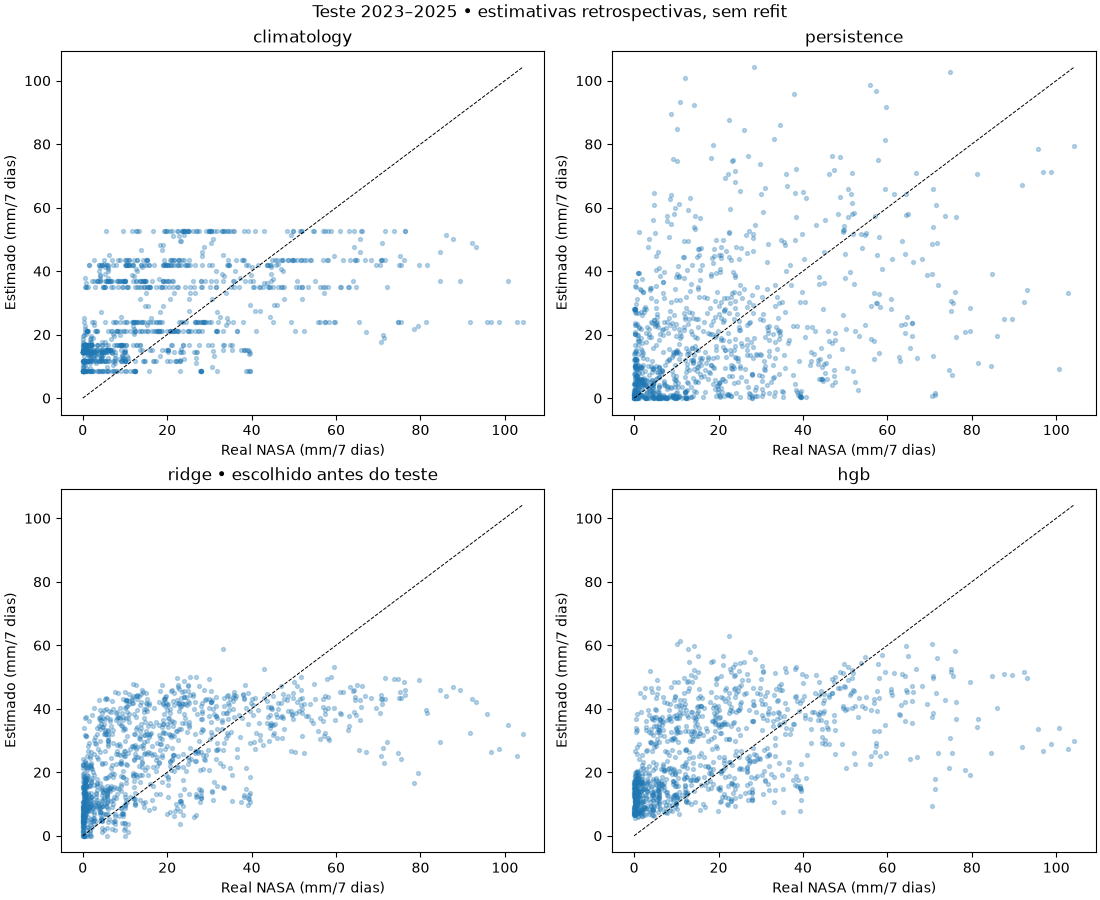

**Figura 9.** Real versus estimado no teste original; não é uma nova previsão.

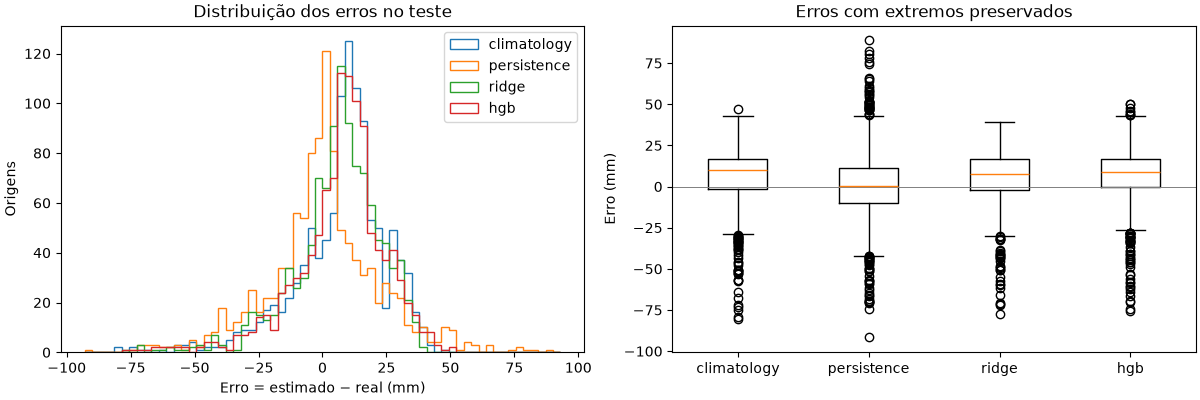

**Figura 10.** Distribuições de erros do teste, preservando extremos e direção do viés.

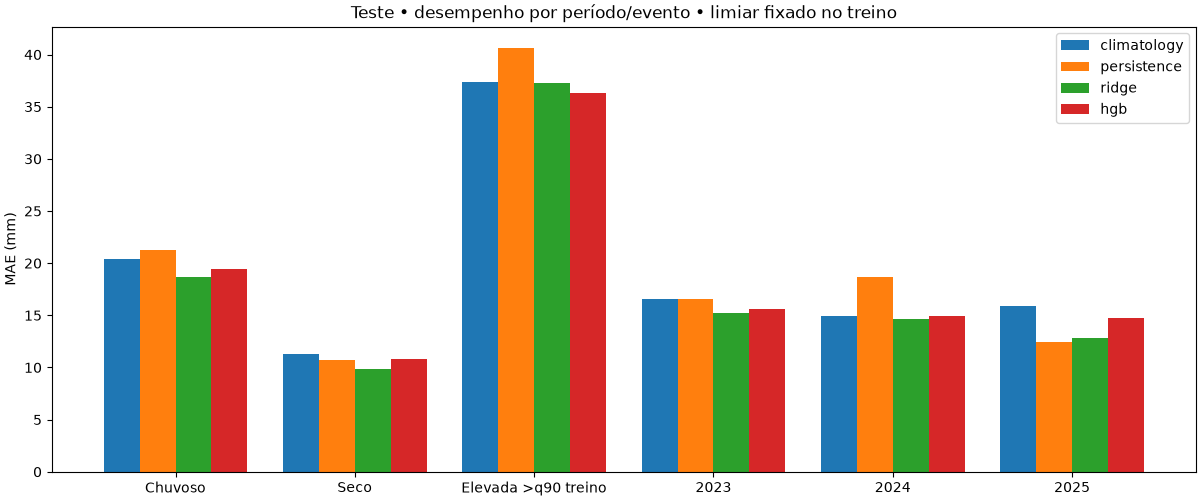

**Figura 11.** MAE por época, ano e chuva elevada; recortes sobrepostos não somam contagens.

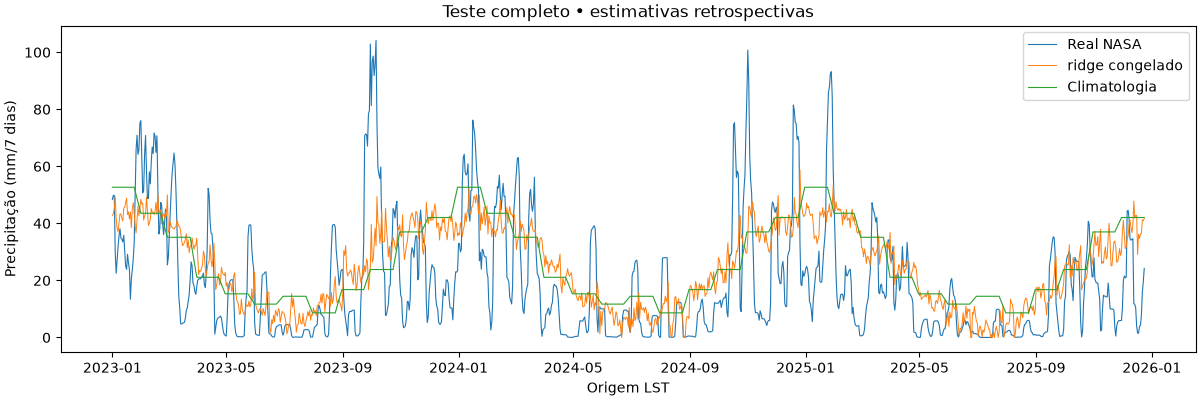

**Figura 12.** Série de alvos e estimativas já arquivadas; janelas consecutivas se sobrepõem.

In [13]:
show_figure('outputs/agua03/figures/01_real_estimado.png',
            '**Figura 9.** Real versus estimado no teste original; não é uma nova previsão.')
show_figure('outputs/agua03/figures/02_erros.png',
            '**Figura 10.** Distribuições de erros do teste, preservando extremos e direção do viés.')
show_figure('outputs/agua03/figures/03_periodos.png',
            '**Figura 11.** MAE por época, ano e chuva elevada; recortes sobrepostos não somam contagens.')
show_figure('outputs/agua03/figures/04_serie_teste.png',
            '**Figura 12.** Série de alvos e estimativas já arquivadas; janelas consecutivas se sobrepõem.')

**Interpretação dos gráficos:** dispersão e erros evidenciam limitação nos picos; menor MAE médio não significa previsão confiável de extremos. Outubro–março e abril–setembro têm escalas distintas de chuva, portanto menor erro absoluto não implica maior habilidade. Há diferenças por ano e as séries não mostram um serviço em tempo real. Os pontos não foram removidos para melhorar desempenho.

In [14]:
high = metrics.loc[metrics.block.eq('test') & metrics.group.eq('high_gt_train_q90')]
display(high[['method','n','mae_mm','rmse_mm','bias_mm','gain_mae_pct']])
threshold = frozen['q90_high_rain_train_mm']
extreme = test_predictions.loc[test_predictions.y_mm.gt(threshold)]
assert len(extreme) == 60
print('Limiar prévio >q90 do treino:', round(threshold,3), 'mm')
print('Subestimações Ridge nas chuvas elevadas:', int(extreme.ridge.lt(extreme.y_mm).sum()), '/', len(extreme))
uncertainty = pd.read_csv(ROOT/'outputs/agua03/uncertainty.csv')
display(uncertainty.loc[uncertainty.block.eq('test') & uncertainty.method.eq('ridge')])

,method,n,mae_mm,rmse_mm,bias_mm,gain_mae_pct
12,climatology,60,37.3492,41.4726,-37.3492,0.0000
13,persistence,60,40.6592,46.0487,-39.5892,-8.8621
14,ridge,60,37.2926,40.3793,-37.2926,0.1516
15,hgb,60,36.2698,40.5732,-36.2698,2.8902


Limiar prévio >q90 do treino: 61.844 mm
Subestimações Ridge nas chuvas elevadas: 60 / 60


,block,method,block_days,repeats,mae_reduction_mm,ci95_low_mm,ci95_high_mm,valid_block_starts
12,test,ridge,14,1000,1.5623,0.7566,2.2506,1076
13,test,ridge,28,1000,1.5623,0.6945,2.3480,1062
14,test,ridge,56,1000,1.5623,0.5991,2.3246,1034


**Resposta à pergunta de pesquisa:** a Ridge melhora MAE em 6,87% na validação e 9,88% no teste. No teste, MAE=14,245 mm, RMSE=18,069 mm, viés=+5,650 mm e R²=0,226. O HGB tem ganho médio de 4,50%. Esses resultados sustentam apenas vantagem média retrospectiva neste recorte.

Nas chuvas elevadas (>q90 do treino, 61,844 mm; n=60), a Ridge ganha só 0,15%, tem MAE=37,293 mm e subestima todos os alvos desse recorte. Isso limita qualquer inferência sobre antecipação de picos ou recuperação hídrica.

O bootstrap **já arquivado**, com blocos de 28 dias, estima redução média pareada de MAE de 1,562 mm e intervalo aproximado de 95% [0,695; 2,348] mm; sensibilidades 14/56 dias aparecem na tabela. Nesta execução não se reamostrou para obter um intervalo mais favorável. Janelas compartilham seis dias; teste de três anos e sazonalidade limitam a aproximação. Não há 1.089 observações independentes. MAE não é uma margem individual ±14,245 mm; intervalo de previsão individual não foi calibrado.

Diferenças treino/avaliação podem envolver sobreajuste e mudança de distribuição. Agregados do teste já haviam sido vistos na EDA, portanto o cegamento humano é parcial. Não houve alteração do protocolo para favorecer o resultado.

## 8. Riscos, supervisão humana e recomendações

Os quantis descrevem posição no histórico; não classificam crise hídrica validada. Superestimar chuva pode gerar falsa tranquilidade se interpretado como recuperação de disponibilidade; subestimar pode aumentar avisos desnecessários. MAE simétrico não estima esses custos. Sem rótulos de escassez e custo de decisão, não se calculam falsos positivos/negativos de um alerta de abastecimento.

O contrato mantém `decision_authorized=false`, `retrospectivo_sem_servico` e nível nulo para estimativas experimentais. Não há notificação ou racionamento automatizado. Restrições de abastecimento exigem avaliação e validação dos gestores competentes.

| Recomendação | Evidência e condição |
|---|---|
| Acompanhar sazonalidade e cobertura | 73,64% da chuva em outubro–março; interpretar indicadores por mês e período |
| Qualificar volume e vazões | Esclarecer `isValid`, janela, timezone e metadados antes de admitir Sabesp à análise |
| Validar externamente | Selecionar estações com cobertura/relevo/janela compatíveis; E3-097 é insuficiente |
| Novo protocolo prospectivo | Verificar latência e vintages em período independente, definir alvo hídrico e custos com gestores |
| Preservar incertezas e responsabilidade | Não comunicar crise atual nem economia de água, produtividade ou benefício social não medidos |

**Pendências reais de conformidade:** caracterização integrada de disponibilidade, condição atual validada e antecipação de escassez não foram demonstradas. A documentação das dificuldades é permitida pelo enunciado, mas não equivale a atender esses objetivos. O recorte espacial não representa igualmente todos os territórios da RMSP. Os dados analíticos são ambientais, sem dados pessoais da população; não houve avaliação de grupos vulneráveis.

## 9. Evidências finais e integridade
A última célula confere novamente os mesmos arquivos preservados e apresenta os resultados da suíte da sprint. Essa tabela é a leitura do registro anterior de testes; não afirma que a suíte foi executada dentro do kernel. As asserções desta execução constam nas células acima.

In [15]:
for relative, expected in snapshot.items():
    assert digest(ROOT/relative) == expected, relative
checks = read_json('outputs/entrega/checks.json')
assert checks['status'] == 'passed'
import xml.etree.ElementTree as ET
xml = ET.parse(ROOT/'outputs/entrega/test-results.xml').getroot()
cases = list(xml.iter('testcase'))
assert not list(xml.iter('failure')) and not list(xml.iter('error'))
display(pd.DataFrame([{'arquivo': '131 arquivos preservados', 'resultado': 'SHA-256 idênticos antes/depois'},
                      {'arquivo': 'métricas dos dois modelos', 'resultado': 'recalculadas, idênticas às arquivadas'},
                      {'arquivo': 'teste original / modelos', 'resultado': 'sem abertura, fit, predict ou joblib.load'},
                      {'arquivo': 'suíte registrada da sprint', 'resultado': f'{len(cases)} testes aprovados; 2 de fitting desmarcados'}]))
print('Notebook concluído: análises executadas com os experimentos originais preservados.')

,arquivo,resultado
0,131 arquivos preservados,SHA-256 idênticos antes/depois
1,métricas dos dois modelos,"recalculadas, idênticas às arquivadas"
2,teste original / modelos,"sem abertura, fit, predict ou joblib.load"
3,suíte registrada da sprint,59 testes aprovados; 2 de fitting desmarcados


Notebook concluído: análises executadas com os experimentos originais preservados.


## 10. Referências e materiais que acompanham a entrega

1. **FIAP.** Data Science and Analytics GS2026-2, “Monitoramento e previsão de riscos hídricos na RMSP”, 6 páginas. Documento fornecido; SHA-256 em `outputs/entrega/enunciado.json`.
2. **NASA POWER.** [Daily Point API](https://power.larc.nasa.gov/docs/services/api/temporal/daily/), [dados e resolução](https://power.larc.nasa.gov/docs/faqs/data/). Extração 06/11/2026; respostas/URLs/horários/unidades em `data/provenance.json` e `data/raw/`.
3. **IBGE.** [Mapa municipal Mogi das Cruzes, 2020](https://geoftp.ibge.gov.br/cartas_e_mapas/mapas_municipais/colecao_de_mapas_municipais/2020/SP/mogi_das_cruzes/3530607_MM.pdf). Coordenadas arredondadas de referência da sede.
4. **Sabesp.** [Portal dos Mananciais — base de dados](https://mananciais.sabesp.com.br/base-dados) e [glossário](https://mananciais.sabesp.com.br/glossario). Consulta 16/11/2026; API v4, elemento 65; originais/URLs/SHA-256 em `outputs/entrega/hidrologia/`.
5. **SP Águas.** [Reservatórios](https://salasituacaosp.spaguas.sp.gov.br/sssp/reservatorios), [vazões](https://salasituacaosp.spaguas.sp.gov.br/sssp/vazoes-comparativo), [SSD](https://cth.daee.sp.gov.br/ssdsp/Mananciais), [banco hidrológico](https://ph.spaguas.sp.gov.br/Fluviometricos), [SIBH](https://apps.spaguas.sp.gov.br/sibh/). Limitações de acesso e amostra E3-097 documentadas.
6. **INMET.** [Históricos](https://portal.inmet.gov.br/dadoshistoricos), catálogo oficial arquivado em `data/comparison/`, consultado em 06/11/2026.
7. **scikit-learn.** [Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html) e [HistGradientBoostingRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html), implementação 1.9.1 preservada.

**Código original:** `pipeline.py`, `eda.py`, `ml.py`, `consolidate.py`. **Pesquisa e reprodução:** `hydrology.py`, `notebook_delivery.py`, `verify_delivery.py` e `requirements*.txt`. **Evidências:** dados, modelos, inventários, protocolo, recibos e gráficos completos no módulo. **Conformidade:** `docs/matriz-conformidade.md`.

A síntese executiva oficial de uma página acompanha este notebook. O relatório PDF de nove páginas é uma alternativa preservada; o aluno pode escolher a opção notebook executado prevista pelo enunciado. Enviar o pacote de apoio para permitir reprodução, além do `.ipynb` e da síntese. Repositório: [matheeusvx/Agro-Brasil](https://github.com/matheeusvx/Agro-Brasil), módulo `analytics/agro-agua/`.